<a href="https://colab.research.google.com/github/anacvetkoo/MOS-projekt/blob/main/notebooks/Ziva_teden3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Živa – 2. teden: Stroški študija in zaslužki v IT

V okviru skupnega projekta *Ali se študij danes še splača?* sem izvedla dve osnovni analizi:

- **RV3:** Spreminjanje objavljenih šolnin v treh skupinah ameriških univerz (2004–2023) ter primerjava šolnin, skupnih stroškov in neto cen na Ivy League (2009–2023).
- **RV5:** Primerjava letnih zaslužkov zaposlenih v računalniških poklicih v ZDA glede na izobrazbo (ACS 2024).

Za RV3 sem uporabila IPEDS in College Scorecard, za RV5 pa IPUMS ACS. Pripravljalna postopka za ACS in zgodovinski College Scorecard sta v ločenih zvezkih `ACS_priprava_IT.ipynb` in `Scorecard_priprava_RV3.ipynb`.


In [1]:
# 1. Uvoz knjižnic in povezava z Google Drive

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from google.colab import drive

drive.mount("/content/drive")

# Določitev poti do podatkov
mapa = Path(
    "/content/drive/MyDrive/FERI/3. letnik/1. semester/MOS/Projekt_teden3"
)

# Preverjanje obstoja mape
if not mapa.is_dir():
    raise FileNotFoundError(f"Mapa ni najdena: {mapa}")

print("Mapa uspešno najdena:", mapa)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Mapa uspešno najdena: /content/drive/MyDrive/FERI/3. letnik/1. semester/MOS/Projekt_teden3


## RV3 – Kako so se spreminjali stroški študija?

Najprej primerjam **tri skupine univerz** (Ivy League, druge zasebne neprofitne štiriletne in javne štiriletne) v obdobju 2004–2023. Nato se osredotočim na **šolnine, skupne stroške in neto cene Ivy League** v obdobju 2009–2023.

- **IPEDS:** `IPEDS_RV3.csv`, `IPEDS_institucije_2004_2024.csv` (pripravila Ana).
- **College Scorecard:** `Scorecard_Ivy_2009_2023.csv` (pripravljeno v pomožnem zvezku).
- **Inflacija:** letni CPI-U; zneske preračunam v **dolarje leta 2023**.

Univerze povezujem po `UNITID` in `leto`. Za javne univerze uporabljam *in-state* šolnine, za zasebne pa `CHG3AY3`.

In [2]:
# RV3: Branje podatkov in določitev univerz Ivy League

# Branje podatkov o šolninah
df_ipeds = pd.read_csv(
    mapa / "IPEDS_RV3.csv",
    usecols=["UNITID", "leto", "CHG2AY3", "CHG3AY3"]
)

# Branje podatkov o vrstah univerz
df_ipeds_institucije = pd.read_csv(
    mapa / "IPEDS_institucije_2004_2024.csv",
    usecols=["UNITID", "leto", "SECTOR"]
)

# Univerze Ivy League in njihovi identifikatorji
ivy_imena = {
    217156: "Brown",
    190150: "Columbia",
    190415: "Cornell",
    182670: "Dartmouth",
    166027: "Harvard",
    186131: "Princeton",
    215062: "UPenn",
    130794: "Yale"
}

ivy_unitid = list(ivy_imena.keys())

# Osnovni pregled podatkov
print("Šolnine:", df_ipeds.shape)
print("Institucije:", df_ipeds_institucije.shape)
print("Obdobje:", df_ipeds["leto"].min(), "–", df_ipeds["leto"].max())

Šolnine: (88205, 4)
Institucije: (147769, 3)
Obdobje: 2004 – 2023


In [3]:
# RV3: Povezovanje in priprava podatkov

# Povezovanje podatkov po univerzi in letu
df_rv3_cene = df_ipeds.merge(
    df_ipeds_institucije,
    on=["UNITID", "leto"],
    how="left",
    validate="one_to_one"
)

# Preverjanje uspešnosti povezovanja
assert df_rv3_cene["SECTOR"].notna().all(), "Nekaterim univerzam manjka oznaka SECTOR."

# Izbor javnih in zasebnih neprofitnih štiriletnih univerz (tudi Ivy League)
df_rv3_cene = df_rv3_cene[
    df_rv3_cene["SECTOR"].isin([1, 2])
].copy()

# Določitev treh skupin univerz
df_rv3_cene["Skupina"] = df_rv3_cene["SECTOR"].map({
    1: "Javne štiriletne",
    2: "Druge zasebne neprofitne"
})

df_rv3_cene.loc[
    df_rv3_cene["UNITID"].isin(ivy_unitid),
    "Skupina"
] = "Ivy League"

# Izbor šolnine glede na vrsto univerze
df_rv3_cene["Solnina_USD"] = np.where(
    df_rv3_cene["SECTOR"] == 1,
    df_rv3_cene["CHG2AY3"],
    df_rv3_cene["CHG3AY3"]
)

# Izločim manjkajoče, ničelne in negativne šolnine,
# saj primerjam objavljene pozitivne zneske šolnin
df_rv3_cene = df_rv3_cene[
    df_rv3_cene["Solnina_USD"] > 0
].copy()

print("Število veljavnih zapisov:", len(df_rv3_cene))
print(df_rv3_cene["Skupina"].value_counts())

Število veljavnih zapisov: 39916
Skupina
Druge zasebne neprofitne    26144
Javne štiriletne            13612
Ivy League                    160
Name: count, dtype: int64


In [4]:
# RV3: Letni indeks inflacije CPI-U (ZDA)

# Prenesem podatke o inflaciji iz spletne zbirke
url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=CPIAUCNS"
df_cpi = pd.read_csv(url)

# Poiščem stolpec z datumom
stolpec_datuma = "observation_date" if "observation_date" in df_cpi.columns else "DATE"

# Iz datuma izluščim leto
df_cpi["leto"] = pd.to_datetime(df_cpi[stolpec_datuma]).dt.year

# Iz mesečnih vrednosti izračuna letno povprečje
df_cpi_letni = df_cpi.groupby("leto", as_index=False)["CPIAUCNS"].mean()

# Obdržim samo leta, ki jih potrebujem
df_cpi_letni = df_cpi_letni[df_cpi_letni["leto"].between(2004, 2023)].copy()
df_cpi_letni = df_cpi_letni.rename(columns={"CPIAUCNS": "CPI"})

# Preveri podatke
assert len(df_cpi_letni) == 20 and df_cpi_letni["CPI"].notna().all()

# Poiščem CPI za leto 2023 - uporabim za preračun šolnin v dolarje leta 2023
cpi_2023 = df_cpi_letni.loc[df_cpi_letni["leto"] == 2023, "CPI"].iloc[0]

print("CPI: 2004–2023, referenčno leto 2023")

CPI: 2004–2023, referenčno leto 2023


In [5]:
# RV3: Mediane šolnin in primerjava rasti med skupinami

df_rv3_trend = df_rv3_cene.groupby(["leto", "Skupina"]).agg(
    mediana_solnine=("Solnina_USD", "median"),
    stevilo_univerz=("UNITID", "nunique")
).reset_index()

# Prilagoditev za inflacijo v dolarje leta 2023
df_rv3_trend = df_rv3_trend.merge(df_cpi_letni, on="leto", validate="many_to_one")
df_rv3_trend["realna_solnina"] = df_rv3_trend["mediana_solnine"] * cpi_2023 / df_rv3_trend["CPI"]

# Primerjava prvega in zadnjega leta
pregled_rv3 = df_rv3_trend[df_rv3_trend["leto"].isin([2004, 2023])].pivot(
    index="Skupina", columns="leto",
    values=["mediana_solnine", "realna_solnina", "stevilo_univerz"]
)
pregled_rv3.columns = [
    "Nominalno_2004", "Nominalno_2023", "Realno_2004", "Realno_2023", "Univerze_2004", "Univerze_2023"
]
pregled_rv3["Nominalna_rast_pct"] = ((pregled_rv3["Nominalno_2023"] / pregled_rv3["Nominalno_2004"] - 1) * 100).round(1)
pregled_rv3["Realna_rast_pct"] = ((pregled_rv3["Realno_2023"] / pregled_rv3["Realno_2004"] - 1) * 100).round(1)

display(pregled_rv3[["Univerze_2004", "Univerze_2023", "Nominalna_rast_pct", "Realna_rast_pct"]])

ivy = df_rv3_trend[df_rv3_trend["Skupina"] == "Ivy League"]
assert len(ivy) == 20 and (ivy["stevilo_univerz"] == 8).all()

,Univerze_2004,Univerze_2023,Nominalna_rast_pct,Realna_rast_pct
Skupina,,,,
Druge zasebne neprofitne,1276.0,1309.0,98.2,22.8
Ivy League,8.0,8.0,115.7,33.7
Javne štiriletne,596.0,777.0,90.6,18.1


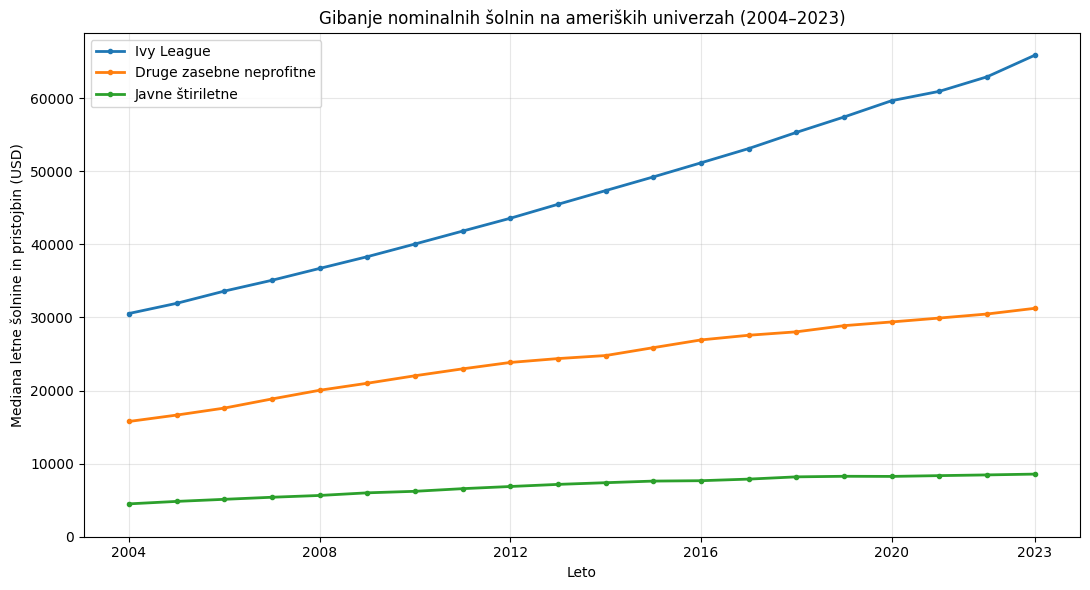

In [6]:
# RV3: Gibanje šolnin po skupinah univerz

plt.figure(figsize=(11, 6))

# Izris treh skupin univerz
skupine = [
    "Ivy League",
    "Druge zasebne neprofitne",
    "Javne štiriletne"
]

for skupina in skupine:
    podatki = df_rv3_trend[df_rv3_trend["Skupina"] == skupina]

    plt.plot(
        podatki["leto"],
        podatki["mediana_solnine"],
        marker="o",
        markersize=3,
        linewidth=2,
        label=skupina
    )

# Oblikovanje grafa
plt.title("Gibanje nominalnih šolnin na ameriških univerzah (2004–2023)")
plt.xlabel("Leto")
plt.ylabel("Mediana letne šolnine in pristojbin (USD)")
plt.xticks([2004, 2008, 2012, 2016, 2020, 2023])
plt.ylim(bottom=0)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

# Shranjevanje grafa
mapa_grafi = mapa / "grafi"
mapa_grafi.mkdir(exist_ok=True)

plt.savefig(mapa_grafi / "RV3_trend_skupine_2004_2023.png", dpi=300)
plt.show()

### Ugotovitve – primerjava treh skupin

- Med letoma **2004 in 2023** so šolnine nominalno zrasle v vseh treh skupinah. Najvišje objavljene šolnine je imela Ivy League.
- **Nominalna / realna rast mediane:** Ivy League **115,7 % / 33,7 %**, druge zasebne neprofitne **98,2 % / 22,8 %**, javne štiriletne **90,6 % / 18,1 %**.
- Torej so se šolnine v vseh skupinah povečale **tudi hitreje od splošne inflacije**, najbolj pri Ivy League.
- **Omejitve:** graf prikazuje nominalne zneske; pri javnih univerzah uporabljam *in-state* šolnine. Nabor institucij z veljavnimi podatki se po letih spreminja. Vsaka univerza ima pri mediani enako težo.

In [7]:
# RV3: Povezovanje podatkov o stroških Ivy League

# Preberem neto cene in skupne stroške iz College Scorecard
df_neto_ivy = pd.read_csv(
    mapa / "Scorecard_Ivy_2009_2023.csv",
    usecols=["UNITID", "leto", "NPT4_PRIV", "COSTT4_A"]
)

# Iz IPEDS izberem šolnine univerz Ivy League
df_ivy_solnine = df_rv3_cene[
    df_rv3_cene["Skupina"] == "Ivy League"
][["UNITID", "leto", "Solnina_USD"]]

# Podatke povežem po univerzi in letu
df_ivy_stroski = df_neto_ivy.merge(
    df_ivy_solnine,
    on=["UNITID", "leto"],
    validate="one_to_one"
)

# Preverim število zapisov in manjkajoče vrednosti
assert len(df_ivy_stroski) == 120 and not df_ivy_stroski.isna().any().any(), "Preveri podatke Ivy League."

print("Povezanih zapisov:", len(df_ivy_stroski), "(8 univerz × 15 let)")

Povezanih zapisov: 120 (8 univerz × 15 let)


In [8]:
# RV3: Mediane Ivy League in nominalna/realna rast stroškov

# Trije stroškovni kazalniki
kazalniki = {
    "Šolnina": "Solnina_USD",
    "Skupni stroški": "COSTT4_A",
    "Neto cena": "NPT4_PRIV"
}

# Izračun letnih median osmih univerz in dodajanje CPI
df_ivy_trend = df_ivy_stroski.groupby(
    "leto", as_index=False
)[list(kazalniki.values())].median()

df_ivy_trend = df_ivy_trend.merge(
    df_cpi_letni, on="leto", validate="one_to_one"
)

# Preračun vseh treh kazalnikov v dolarje leta 2023
for stolpec in kazalniki.values():
    df_ivy_trend[stolpec + "_realno"] = (
        df_ivy_trend[stolpec] * cpi_2023 / df_ivy_trend["CPI"]
    )

# Primerjava prvega in zadnjega leta
prvo = df_ivy_trend[df_ivy_trend["leto"] == 2009].iloc[0]
zadnje = df_ivy_trend[df_ivy_trend["leto"] == 2023].iloc[0]

pregled_ivy = pd.DataFrame([
    {
        "Kazalnik": ime,
        "Nominalna rast (%)": round((zadnje[s] / prvo[s] - 1) * 100, 1),
        "Realna rast (%)": round(
            (zadnje[s + "_realno"] / prvo[s + "_realno"] - 1) * 100, 1
        )
    }
    for ime, s in kazalniki.items()
])

display(pregled_ivy)

,Kazalnik,Nominalna rast (%),Realna rast (%)
0,Šolnina,71.9,21.1
1,Skupni stroški,66.9,17.5
2,Neto cena,60.0,12.7


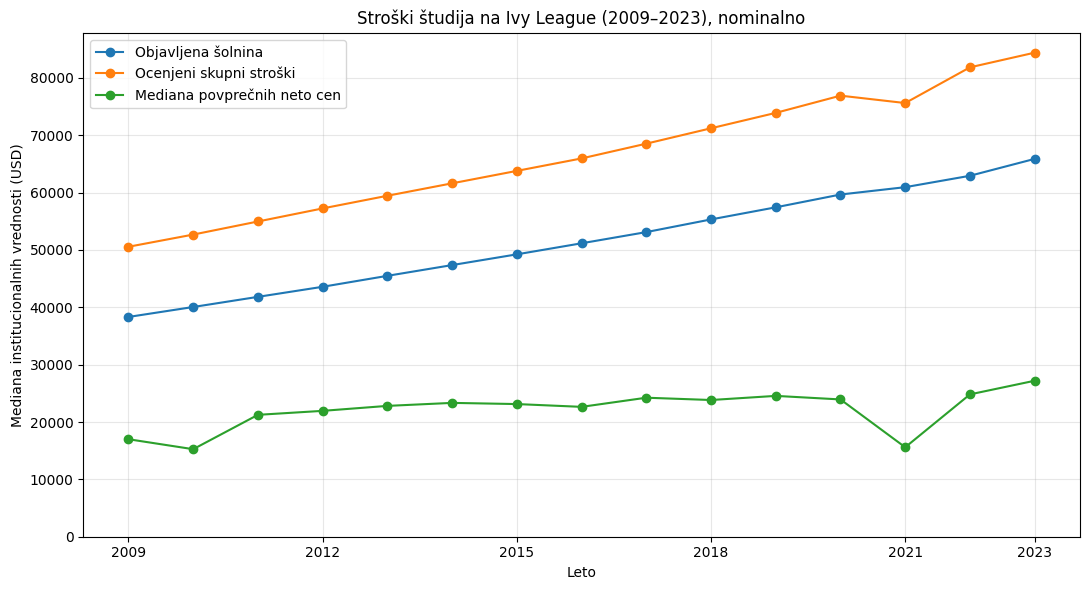

In [9]:
# RV3: Šolnine, skupni stroški in neto cene Ivy League

plt.figure(figsize=(11, 6))

# Prikaz letnih median treh stroškovnih kazalnikov
plt.plot(df_ivy_trend["leto"], df_ivy_trend["Solnina_USD"],
         marker="o", label="Objavljena šolnina")
plt.plot(df_ivy_trend["leto"], df_ivy_trend["COSTT4_A"],
         marker="o", label="Ocenjeni skupni stroški")
plt.plot(df_ivy_trend["leto"], df_ivy_trend["NPT4_PRIV"],
         marker="o", label="Mediana povprečnih neto cen")

plt.title("Stroški študija na Ivy League (2009–2023), nominalno")
plt.xlabel("Leto")
plt.ylabel("Mediana institucionalnih vrednosti (USD)")
plt.xticks([2009, 2012, 2015, 2018, 2021, 2023])
plt.ylim(bottom=0)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

# Shranjevanje grafa v Google Drive
plt.savefig(mapa_grafi / "RV3_ivy_stroski_neto_2009_2023.png", dpi=300)
plt.show()

### Ugotovitve – Ivy League in neto cene

- Med letoma **2009 in 2023** so se šolnine, skupni stroški in neto cene povečali tudi po upoštevanju inflacije. **Realna rast:** šolnine **21,1 %**, skupni stroški **17,5 %**, neto cene **12,7 %**.
- Neto cene so skozi čas bolj nihale kot objavljene šolnine. Leta **2021** se je njihova mediana močno znižala. Upad je bil prisoten pri petih od osmih univerz, vendar iz podatkov ne morem ugotoviti vzroka.
- Razlika med objavljenimi šolninami in neto cenami kaže, zakaj pri presoji finančne dostopnosti študija ni dovolj upoštevati samo objavljene šolnine.

### Metodološke omejitve RV3

- **Primerljivost let:** Podatke IPEDS in College Scorecard sem povezala po univerzi (`UNITID`) in letu. Ker imajo posamezni kazalniki različne poročevalske cikle, ne predstavljajo nujno povsem istega referenčnega obdobja.
- **Neto cena:** `NPT4_PRIV` predstavlja povprečno neto ceno za redne, prvič vpisane dodiplomske študente, ki prejemajo zvezno finančno pomoč (*Title IV*), ne za vse študente. Prikazana je mediana osmih institucionalnih povprečij.
- **Primerjalne skupine:** Pri javnih univerzah sem uporabila *in-state* šolnine. Število univerz z veljavnimi podatki se skozi leta spreminja. Pri izračunu median šolnin sem izključila zapise z ničelnimi, negativnimi ali manjkajočimi vrednostmi.
- **Inflacija:** Nominalne vrednosti sem prilagodila z letnim povprečjem CPI-U in jih izrazila v dolarjih leta 2023. Za posamezno akademsko leto sem uporabila CPI njegovega začetnega koledarskega leta.



---



## RV5 – Zaslužki v računalniških poklicih glede na izobrazbo

Primerjala sem **utežene mediane letnih zaslužkov** za zaposlene v računalniških poklicih (SOC 15-12) v ZDA, stare **25–64 let**, glede na tri skupine izobrazbe: srednja šola/GED, bachelor's degree in master's degree.

Uporabila sem **IPUMS ACS 2024**, pripravljen v `ACS_priprava_IT.ipynb` (datoteka `ACS_2019_2022_2024_IT.csv`). Zajeti so samo zaposleni s pozitivnimi dohodki iz zaposlitve.

Pri izračunu median sem uporabila **populacijske uteži `PERWT`**, ki upoštevajo različno zastopanost oseb v vzorcu ACS.

Namen analize je **opisati razlike v zaslužkih**, ne oceniti vzročnega učinka izobrazbe ali verjetnosti zaposlitve.

In [10]:
# RV5: Branje podatkov ACS

# Preberem samo stolpce, ki jih potrebujem za analizo
df_acs_it = pd.read_csv(
    mapa / "ACS_2019_2022_2024_IT.csv",
    usecols=["YEAR", "AGE", "EDUCD", "EMPSTAT", "INCWAGE", "PERWT"]
)

# Izberem leto 2024
df_acs_it_2024 = df_acs_it[df_acs_it["YEAR"] == 2024].copy()

print("Število zapisov za leto 2024:", len(df_acs_it_2024))

Število zapisov za leto 2024: 65474


In [11]:
# RV5: Izbor zaposlenih in izobrazbenih skupin

# Kode izobrazbe ACS pretvorim v tri skupine
izobrazba_kode = {
    63: "Srednja šola / GED", 64: "Srednja šola / GED",
    101: "Bachelor's degree", 114: "Master's degree"
}

# Izberem zaposlene, stare 25–64 let, z veljavnimi zaslužki
# in eno od treh izbranih stopenj izobrazbe
maska = (
    df_acs_it_2024["AGE"].between(25, 64)
    & (df_acs_it_2024["EMPSTAT"] == 1)
    & (df_acs_it_2024["INCWAGE"] > 0)
    & (~df_acs_it_2024["INCWAGE"].isin([999998, 999999]))
    & (df_acs_it_2024["PERWT"] > 0)
    & (df_acs_it_2024["EDUCD"].isin(izobrazba_kode))
)

# Obdržim izbrane osebe in dodam razumljiva imena izobrazbe
df_rv5 = df_acs_it_2024.loc[maska].copy()
df_rv5["Izobrazba"] = df_rv5["EDUCD"].map(izobrazba_kode)

# Določim vrstni red izobrazbenih skupin
vrstni_red = ["Srednja šola / GED", "Bachelor's degree", "Master's degree"]

print("Zapisi po izobrazbi:")
print(df_rv5["Izobrazba"].value_counts().reindex(vrstni_red))
print("Skupaj:", len(df_rv5))

Zapisi po izobrazbi:
Izobrazba
Srednja šola / GED     2563
Bachelor's degree     23398
Master's degree       11401
Name: count, dtype: int64
Skupaj: 37362


In [12]:
# RV5: Utežene mediane zaslužkov

# Funkcija izračuna mediano ob upoštevanju populacijskih uteži
def utezena_mediana(vrednosti, utezi):
    indeksi = np.argsort(vrednosti)          # določi vrstni red zaslužkov od najmanjšega do največjega
    x = np.asarray(vrednosti)[indeksi]       # razvrsti zaslužke po velikosti
    w = np.asarray(utezi)[indeksi]           # razvrsti uteži v enakem vrstnem redu kot zaslužke
    return x[np.searchsorted(np.cumsum(w), w.sum() / 2)]  # vrne zaslužek, kjer seštevek uteži doseže polovico vseh uteži

# Za vsako izobrazbeno skupino izračunam uteženo mediano zaslužka
rezultati = []

for skupina in vrstni_red:
    podatki = df_rv5[df_rv5["Izobrazba"] == skupina]

    rezultati.append({
        "Izobrazba": skupina,
        "Stevilo_oseb": len(podatki),
        "Mediana_USD": utezena_mediana(
            podatki["INCWAGE"], podatki["PERWT"]
        )
    })

# Rezultate prikažem v preglednici
df_median = pd.DataFrame(rezultati)
display(df_median)

,Izobrazba,Stevilo_oseb,Mediana_USD
0,Srednja šola / GED,2563,71000
1,Bachelor's degree,23398,107000
2,Master's degree,11401,130000


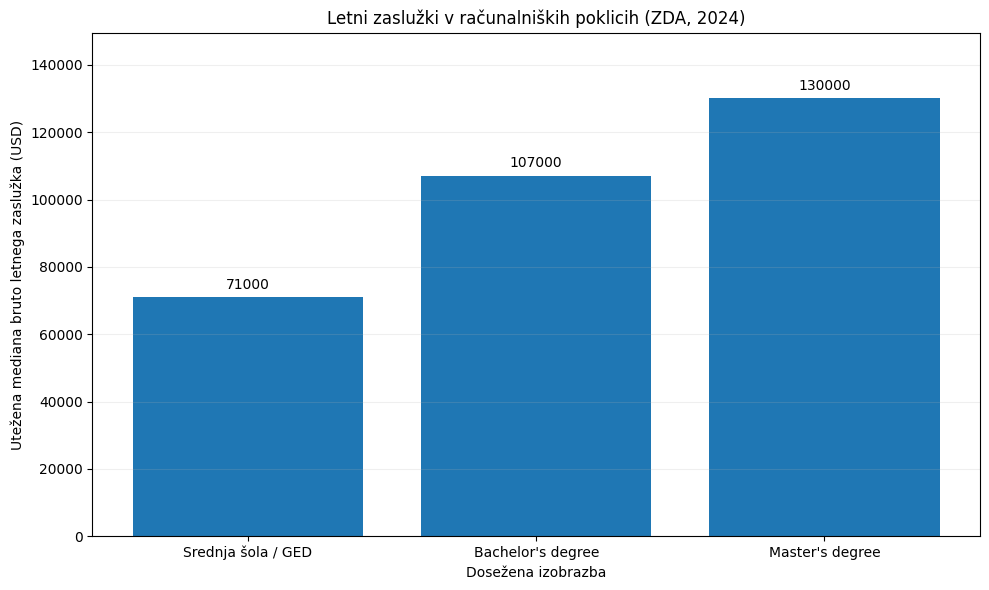

In [13]:
# RV5: Graf median zaslužkov glede na izobrazbo

plt.figure(figsize=(10, 6))

# Narišem stolpce in nadnje izpišem vrednosti v USD
stolpci = plt.bar(df_median["Izobrazba"], df_median["Mediana_USD"])
plt.bar_label(stolpci, fmt="%.0f", padding=4)

# Naslov in oznake osi
plt.title("Letni zaslužki v računalniških poklicih (ZDA, 2024)")
plt.xlabel("Dosežena izobrazba")
plt.ylabel("Utežena mediana bruto letnega zaslužka (USD)")

# Dodam prostor nad stolpci in vodoravne mrežne črte
plt.ylim(0, df_median["Mediana_USD"].max() * 1.15)
plt.grid(axis="y", alpha=0.2)

# Uredim postavitev in shranim graf
plt.tight_layout()
plt.savefig(mapa_grafi / "RV5_it_zasluzki_izobrazba_2024.png", dpi=300)
plt.show()

### Ugotovitve – zaslužki glede na izobrazbo

- **Srednja šola/GED:** utežena mediana letnega zaslužka znaša **71.000 USD**.
- **Bachelor's degree:** mediana znaša **107.000 USD**, kar je 36.000 USD več kot pri srednji šoli/GED.
- **Master's degree:** mediana znaša **130.000 USD**, kar je največ med analiziranimi skupinami.
- Zaposleni z višjo izobrazbo imajo v izbranih računalniških poklicih višje mediane zaslužkov. Vendar to ne dokazuje, da višja izobrazba sama povzroča višje zaslužke.

### Metodološke omejitve RV5

- Analiza vključuje **37.362 zapisov** zaposlenih v računalniških poklicih, starih 25–64 let, s pozitivnimi zaslužki. Pri izračunu median sem uporabila populacijske uteži `PERWT`.
- `INCWAGE` predstavlja letni zaslužek iz zaposlitve, ne začetne plače. Analiza ne ločuje zaposlenih s polnim in krajšim delovnim časom.
- Na razlike v zaslužkih lahko vplivajo tudi delovne izkušnje, starost, vrsta poklica in druge značilnosti.
- Primerjala sem samo tri izobrazbene skupine. Ker sem vključila le osebe, ki že delajo v računalniških poklicih, analiza ne prikazuje verjetnosti zaposlitve v IT.

**Vir:** IPUMS USA – ACS 2024. Analiza vključuje izbrane računalniške poklice iz skupine SOC 15-12, določene na podlagi OCCSOC, in ne celotnega IT-sektorja.